# 3.1.2. Линейная и множественная линейная регрессия

**Проект:** предиктивное обслуживание промышленного оборудования  
**Источник:** SQL-представление `v_predictive_maintenance_ml` базы `manufacturing`  
**Файл:** `manufacturing_ml_dataset.csv`

Работа сделана на основе датасета, который был использован для промежуточной аттестации.   
Бинарная переменная `failure_next_6h` не подходит для линейной регрессии, поэтому нужно сформулировать отдельную регрессионную задачу.


# Задание: Выберите вещественную переменную в качестве таргета и несколько объясняющих переменных

## 1. Постановка задачи

**Бизнес-задача:** оценивать среднюю мощность оборудования за час, чтобы анализировать режимы энергопотребления и выявлять отклонения от ожидаемого уровня.

**Задача машинного обучения:** построить модель регрессии, предсказывающую вещественную переменную `power_avg_1h` — среднюю мощность оборудования за предыдущий час, кВт.

### Выбранные объясняющие переменные

- `temperature_avg_1h` — средняя температура за час;
- `nominal_power_kw` — номинальная мощность оборудования;
- `machine_age_years` — возраст машины;
- `readings_count_1h` — количество показаний сенсоров за час;
- `out_of_range_count_1h` — количество показаний вне нормативного диапазона;
- `breakdowns_before` — число прошлых поломок до момента наблюдения;
- `maintenance_last_30d` — число обслуживаний за последние 30 дней;
- `machine_type_code` — тип оборудования, категориальный признак.

Идентификаторы `machine_id` и `machine_code`, а также будущая цель `failure_next_6h` не используются как объясняющие признаки. Это позволяет избежать запоминания отдельных объектов и смешения регрессионной задачи с прогнозом будущей поломки.


## 2. Подключение библиотек


In [12]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

RANDOM_STATE = 42


## 3. Загрузка данных

Датасет `manufacturing_ml_dataset.csv`.


In [13]:
from pathlib import Path

PROJECT_DIR = Path("/home/lova595/Рабочий стол/иннополис")
DATA_PATH = PROJECT_DIR / "база данных" / "manufacturing_ml_dataset.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Файл не найден: {DATA_PATH}")

print(f"Файл найден: {DATA_PATH}")


Файл найден: /home/lova595/Рабочий стол/иннополис/база данных/manufacturing_ml_dataset.csv


In [14]:
df = pd.read_csv(
    DATA_PATH,
    parse_dates=["prediction_time"]
)

print(
    f"Размер исходной таблицы: "
    f"{df.shape[0]:,} строк × {df.shape[1]} столбцов"
)

display(df.head())

Размер исходной таблицы: 17,403 строк × 40 столбцов


,machine_id,machine_code,machine_type_code,line_id,prediction_time,machine_age_years,nominal_power_kw,readings_count_1h,out_of_range_count_1h,temperature_avg_1h,temperature_min_1h,temperature_max_1h,temperature_std_1h,temperature_out_of_range_1h,vibration_avg_1h,vibration_min_1h,vibration_max_1h,vibration_std_1h,vibration_out_of_range_1h,power_avg_1h,power_min_1h,power_max_1h,power_std_1h,rpm_avg_1h,rpm_min_1h,rpm_max_1h,rpm_std_1h,pressure_avg_1h,pressure_min_1h,pressure_max_1h,pressure_std_1h,humidity_avg_1h,humidity_min_1h,humidity_max_1h,humidity_std_1h,breakdowns_before,hours_since_last_breakdown,maintenance_last_30d,hours_since_last_maintenance,failure_next_6h
0,29,M-008-01,CNC_MILL,8,2025-01-10 16:00:00+11:00,3.3370,22.0000,136,0,65.7356,55.1603,80.3652,5.3848,0,2.4075,1.1127,3.5109,0.6082,0,1.2232,1.0226,1.4437,0.0962,"2,444.2909","2,153.6655","2,776.9232",147.8383,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,0,NaN,0
1,2,M-001-02,PRESS,1,2025-01-10 17:00:00+11:00,6.5050,30.0000,205,0,69.8676,55.1643,85.3239,6.2580,0,NaN,NaN,NaN,NaN,0,1.9018,1.7123,2.1424,0.1021,NaN,NaN,NaN,NaN,81.1822,74.4858,90.2300,3.7037,NaN,NaN,NaN,NaN,0,NaN,0,NaN,0
2,4,M-001-04,CNC_MILL,1,2025-01-10 17:00:00+11:00,3.8440,22.0000,68,0,64.5500,53.8869,78.3736,6.4092,0,2.3260,1.7124,3.1240,0.3885,0,1.1603,1.0792,1.2380,0.0500,"2,413.8897","2,152.2816","2,678.2842",163.1264,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,0,NaN,0
3,29,M-008-01,CNC_MILL,8,2025-01-10 17:00:00+11:00,3.3380,22.0000,232,0,68.5656,55.9920,91.6056,5.8926,0,2.5250,1.6584,3.6639,0.4728,0,1.2901,1.1101,1.4714,0.0926,"2,496.6064","2,255.5292","2,882.5159",134.8627,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,0,NaN,0
4,4,M-001-04,CNC_MILL,1,2025-01-10 18:00:00+11:00,3.8440,22.0000,172,0,66.2371,56.5269,74.5081,5.0304,0,2.4612,1.0851,3.4731,0.5089,0,1.2215,1.0615,1.3548,0.0663,"2,521.2391","2,109.1175","2,951.5062",169.6876,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,0,NaN,0


## 4. Формирование выборки для регрессии


In [15]:
target_col = "power_avg_1h"

numeric_features = [
    "temperature_avg_1h",
    "nominal_power_kw",
    "machine_age_years",
    "readings_count_1h",
    "out_of_range_count_1h",
    "breakdowns_before",
    "maintenance_last_30d",
]

categorical_features = ["machine_type_code"]
selected_cols = ["prediction_time", target_col] + numeric_features + categorical_features

missing_cols = sorted(set(selected_cols) - set(df.columns))
if missing_cols:
    raise ValueError(f"В таблице отсутствуют столбцы: {missing_cols}")

reg_df = df[selected_cols].copy()

quality = pd.DataFrame({
    "dtype": reg_df.dtypes.astype(str),
    "missing_count": reg_df.isna().sum(),
    "missing_percent": (reg_df.isna().mean() * 100).round(3),
    "unique_values": reg_df.nunique(dropna=False),
})
display(quality)
print("Полных дубликатов:", reg_df.duplicated().sum())


,dtype,missing_count,missing_percent,unique_values
prediction_time,"datetime64[us, UTC+11:00]",0,0.0000,2829
power_avg_1h,float64,46,0.2640,17358
temperature_avg_1h,float64,0,0.0000,17403
nominal_power_kw,float64,0,0.0000,7
machine_age_years,float64,0,0.0000,4298
readings_count_1h,int64,0,0.0000,468
out_of_range_count_1h,int64,0,0.0000,133
breakdowns_before,int64,0,0.0000,7
maintenance_last_30d,int64,0,0.0000,4
machine_type_code,str,0,0.0000,7


Полных дубликатов: 0


### Очистка целевой переменной

Линейная регрессия не может обучаться на строках без известного значения target. Поэтому удаляются только наблюдения с пропуском `power_avg_1h`. Пропуски в других столбцах на этом этапе не удаляются автоматически.


In [16]:
rows_before = len(reg_df)
reg_df = reg_df.dropna(subset=[target_col]).copy()
rows_removed = rows_before - len(reg_df)

print(f"Удалено строк без target: {rows_removed}")
print(f"Осталось наблюдений: {len(reg_df):,}")
print("Пропуски в выбранных признаках:", int(reg_df[numeric_features + categorical_features].isna().sum().sum()))


Удалено строк без target: 46
Осталось наблюдений: 17,357
Пропуски в выбранных признаках: 0


## 5. Характеристики целевой переменной


,count,mean,std,min,25%,50%,75%,max
power_avg_1h,"17,357.0000",2.4989,1.2677,0.4536,1.2895,2.5506,3.6135,4.9751


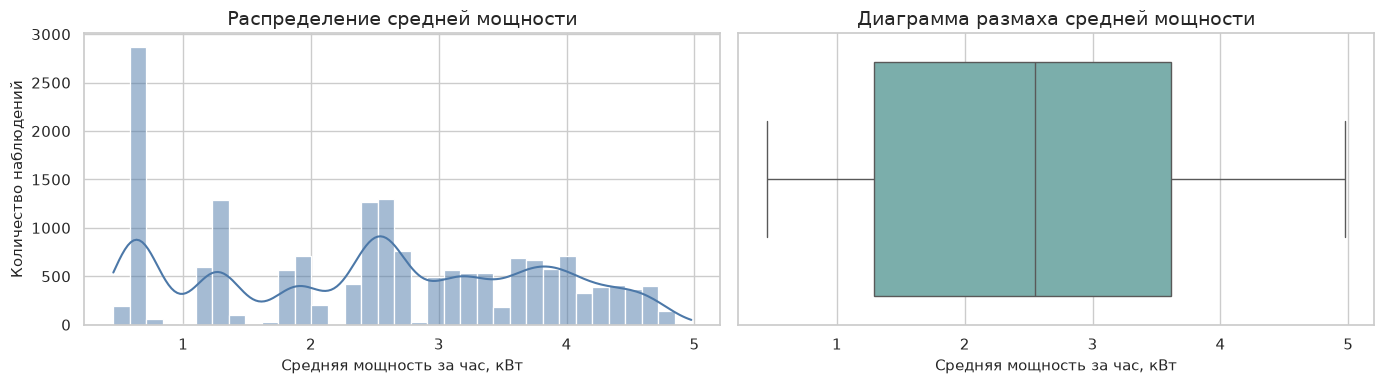

In [17]:
display(reg_df[target_col].describe().to_frame().T)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=reg_df, x=target_col, bins=35, kde=True, ax=axes[0], color="#4C78A8")
sns.boxplot(data=reg_df, x=target_col, ax=axes[1], color="#72B7B2")
axes[0].set_title("Распределение средней мощности")
axes[0].set_xlabel("Средняя мощность за час, кВт")
axes[0].set_ylabel("Количество наблюдений")
axes[1].set_title("Диаграмма размаха средней мощности")
axes[1].set_xlabel("Средняя мощность за час, кВт")
plt.tight_layout()
plt.show()


### Вывод по первому этапу

После удаления строк с неизвестной целевой переменной остаётся **17 357 наблюдений**. Значения `power_avg_1h` лежат примерно в диапазоне от **0,45 до 4,98 кВт**, среднее значение составляет около **2,50 кВт**. В выбранных объясняющих переменных пропусков нет, поэтому их можно использовать без импутации.

Распределение мощности имеет несколько выраженных групп. Это ожидаемо: в выборке представлены разные типы оборудования с различными режимами энергопотребления. На следующем этапе необходимо построить точечные диаграммы и проверить форму зависимости target от каждого числового признака, а влияние типа машины рассмотреть с помощью boxplot.


# Задание: Постройте точечные диаграммыммы (scatterplots) для таргета и каждой фичи, опишите форму взаимосвязи между переменными.

## 6. Анализ взаимосвязи целевой переменной с признаками

Построим точечные диаграммы зависимости средней мощности `power_avg_1h`
от каждого числового признака. Красная линия показывает общее направление
линейной зависимости.

Для категориального признака `machine_type_code` используем stripplot —
категориальный аналог scatterplot, дополненный диаграммой размаха.

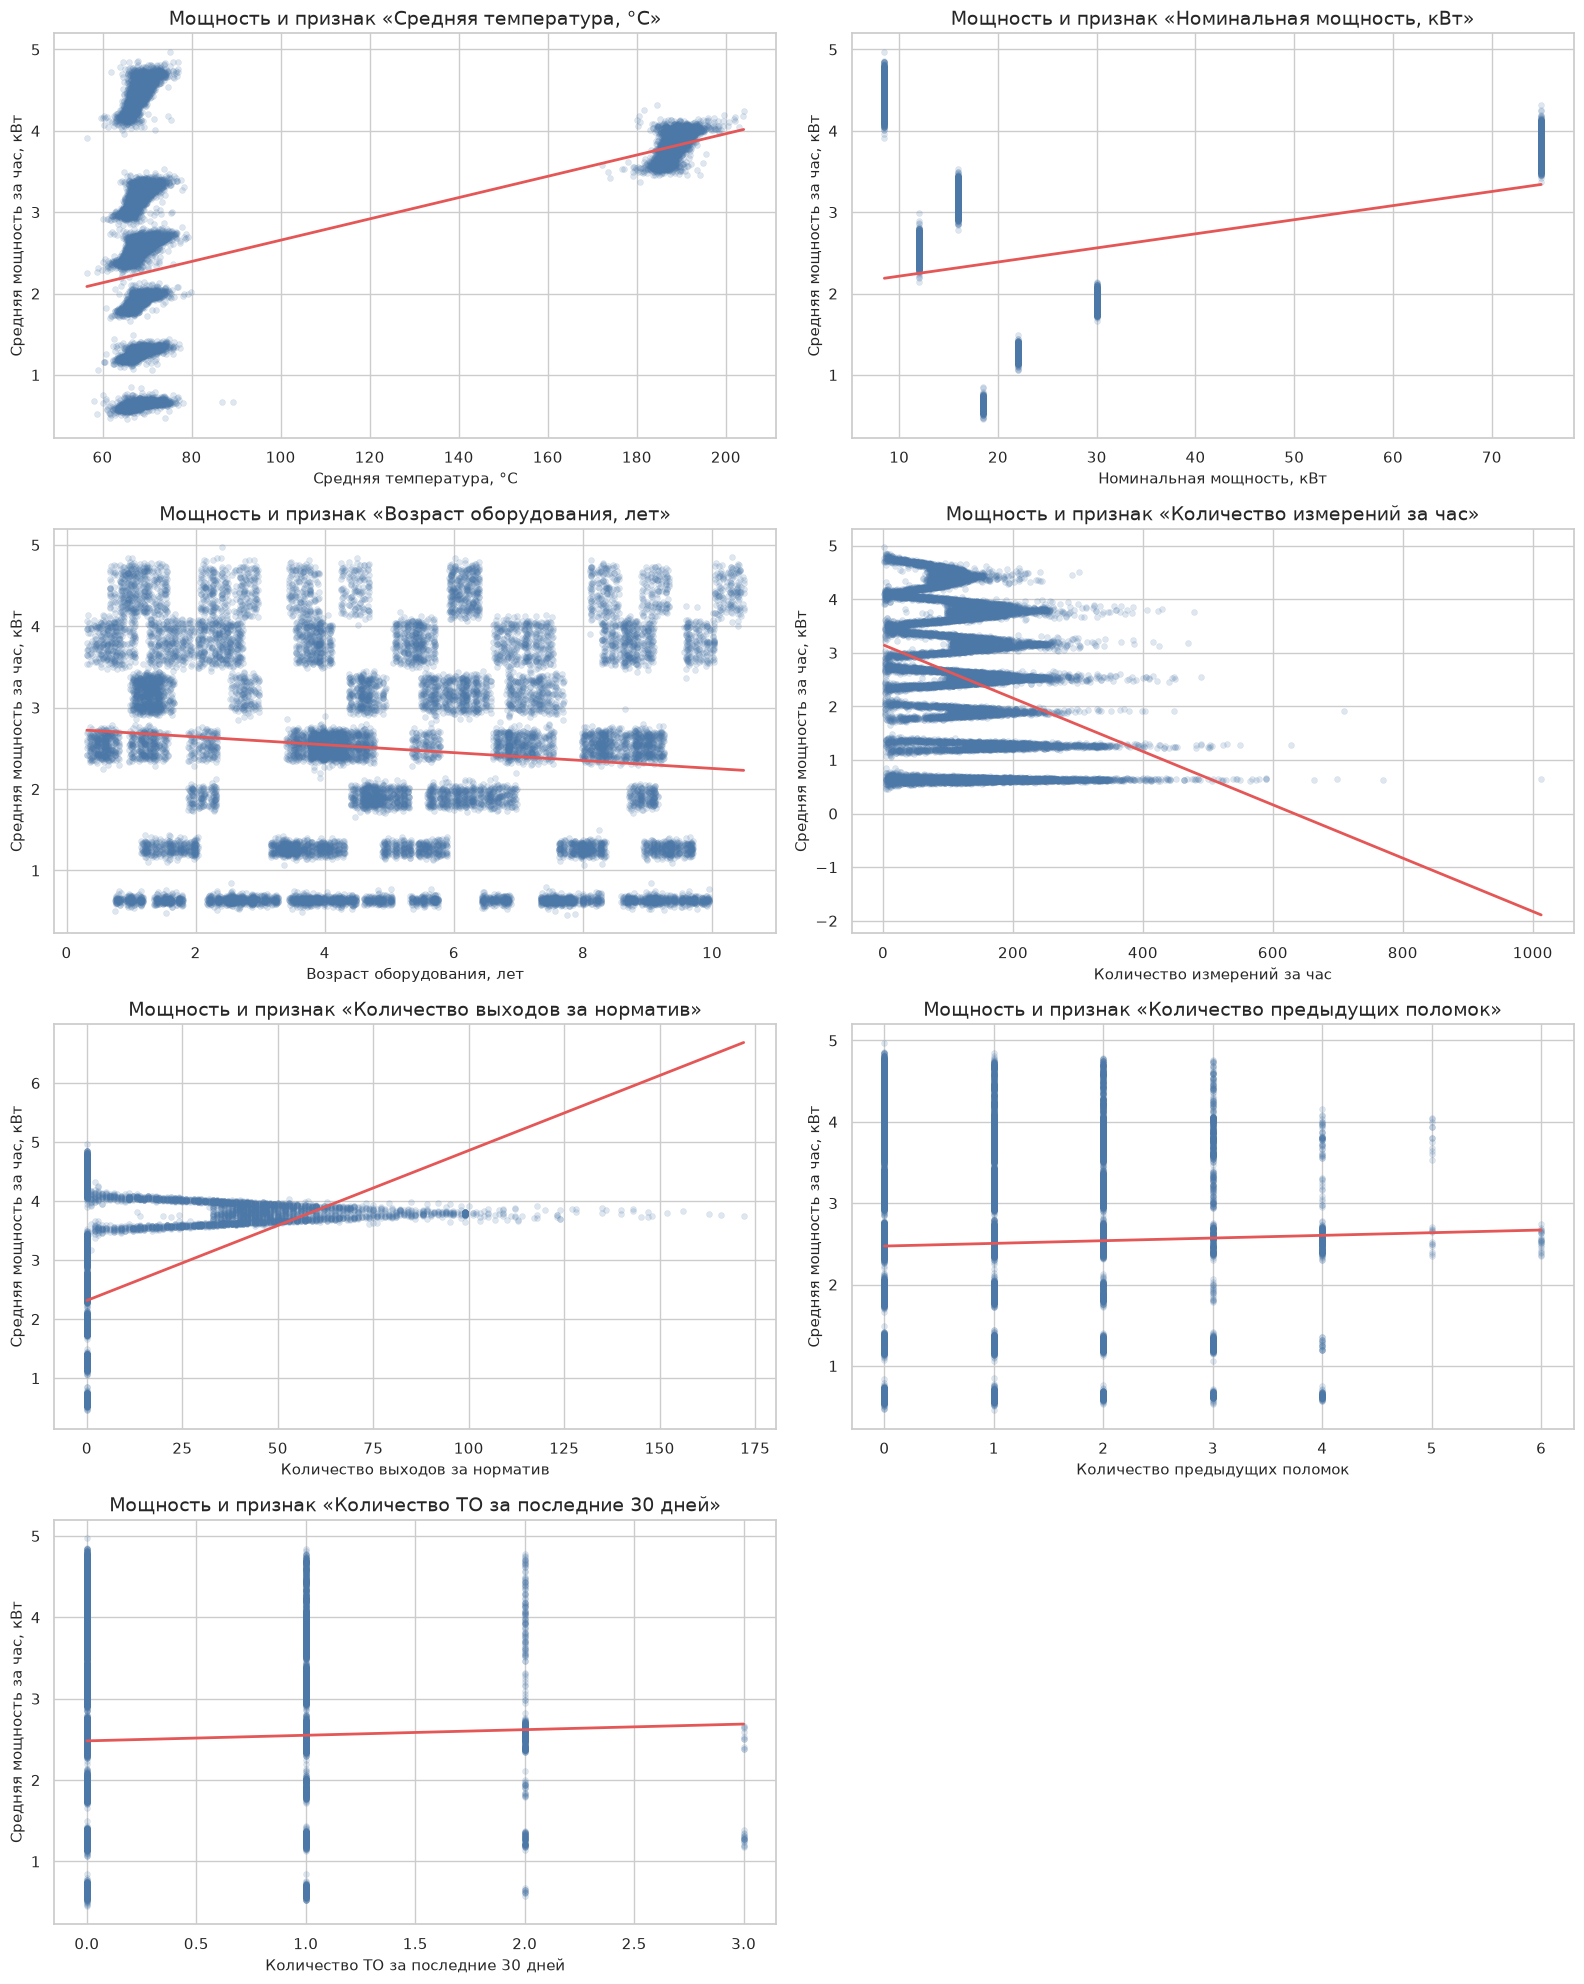

In [18]:
plot_labels = {
    "temperature_avg_1h": "Средняя температура, °C",
    "nominal_power_kw": "Номинальная мощность, кВт",
    "machine_age_years": "Возраст оборудования, лет",
    "readings_count_1h": "Количество измерений за час",
    "out_of_range_count_1h": "Количество выходов за норматив",
    "breakdowns_before": "Количество предыдущих поломок",
    "maintenance_last_30d": "Количество ТО за последние 30 дней",
}

fig, axes = plt.subplots(4, 2, figsize=(16, 20))
axes = axes.flatten()

for ax, feature in zip(axes, numeric_features):
    sns.scatterplot(
        data=reg_df,
        x=feature,
        y=target_col,
        alpha=0.18,
        s=18,
        color="#4C78A8",
        edgecolor=None,
        ax=ax,
    )

    # Общая линия линейного тренда
    sns.regplot(
        data=reg_df,
        x=feature,
        y=target_col,
        scatter=False,
        ci=None,
        color="#E45756",
        line_kws={"linewidth": 2},
        ax=ax,
    )

    ax.set_title(f"Мощность и признак «{plot_labels[feature]}»")
    ax.set_xlabel(plot_labels[feature])
    ax.set_ylabel("Средняя мощность за час, кВт")

# Последняя область не используется
for ax in axes[len(numeric_features):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

Красная линия здесь показывает направление общей линейной зависимости. Она не доказывает причинное влияние признака.

## Численные коэффициенты корреляции

In [19]:
correlation_with_target = (
    reg_df[numeric_features + [target_col]]
    .corr()[target_col]
    .drop(target_col)
    .sort_values(ascending=False)
    .rename("correlation_with_power")
    .to_frame()
)

display(correlation_with_target)

,correlation_with_power
temperature_avg_1h,0.4615
out_of_range_count_1h,0.3843
nominal_power_kw,0.3060
maintenance_last_30d,0.0267
breakdowns_before,0.0256
machine_age_years,-0.1046
readings_count_1h,-0.3104


## Категориальный аналог scatterplot

Для machine_type_code обычная точечная диаграмма не подходит, поскольку тип машины — это категория. Используем boxplot и точки с небольшим случайным смещением.

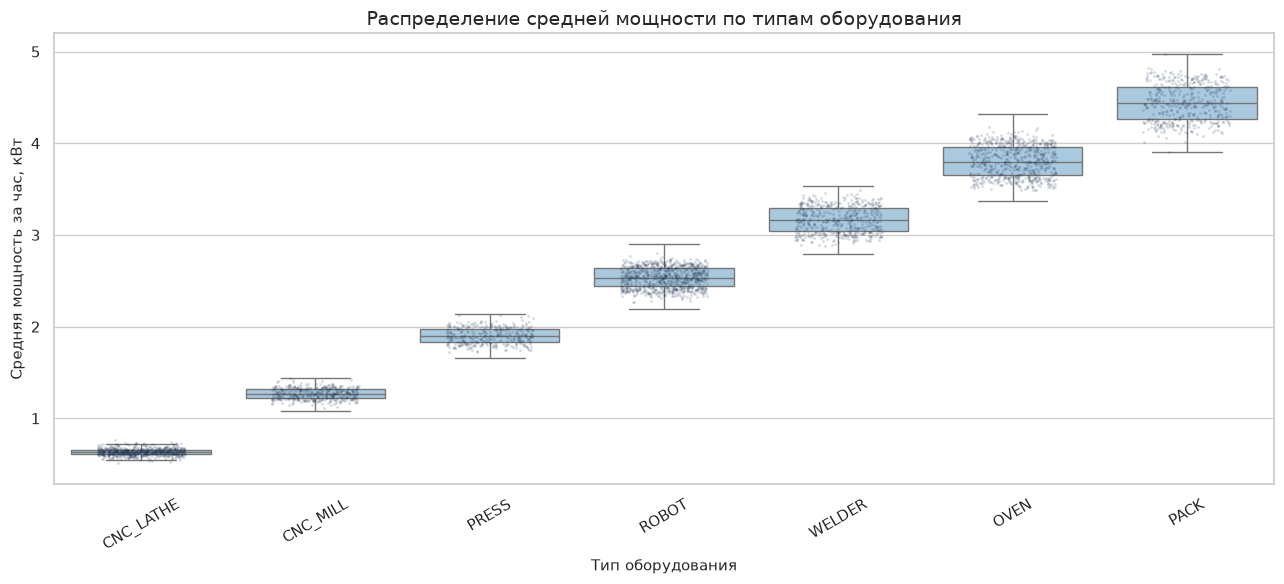

In [20]:
type_order = (
    reg_df.groupby("machine_type_code")[target_col]
    .median()
    .sort_values()
    .index
)

plt.figure(figsize=(13, 6))

sns.boxplot(
    data=reg_df,
    x="machine_type_code",
    y=target_col,
    order=type_order,
    color="#A0CBE8",
    showfliers=False,
)

# Берём часть наблюдений, чтобы точки не перекрывали друг друга
plot_sample = reg_df.sample(
    n=min(4000, len(reg_df)),
    random_state=RANDOM_STATE,
)

sns.stripplot(
    data=plot_sample,
    x="machine_type_code",
    y=target_col,
    order=type_order,
    color="#1F3552",
    alpha=0.18,
    size=2,
    jitter=0.25,
)

plt.title("Распределение средней мощности по типам оборудования")
plt.xlabel("Тип оборудования")
plt.ylabel("Средняя мощность за час, кВт")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Средние значения по типам оборудования

In [21]:
power_by_machine_type = (
    reg_df.groupby("machine_type_code")[target_col]
    .agg(
        observations="count",
        mean_power="mean",
        median_power="median",
        std_power="std",
    )
    .sort_values("mean_power")
    .round(3)
)

display(power_by_machine_type)

,observations,mean_power,median_power,std_power
machine_type_code,,,,
CNC_LATHE,3113,0.6340,0.6340,0.0350
CNC_MILL,1987,1.2680,1.2670,0.0590
PRESS,1502,1.9020,1.8990,0.0850
ROBOT,3762,2.5370,2.5350,0.1130
WELDER,2156,3.1700,3.1680,0.1410
OVEN,2877,3.8040,3.7980,0.1680
PACK,1960,4.4390,4.4360,0.1940


### Выводы о форме взаимосвязей

1. **Средняя температура.** Наблюдается умеренная положительная связь:
   при увеличении температуры средняя мощность в целом возрастает.
   Коэффициент корреляции равен примерно 0,46. При этом на графике заметны
   отдельные группы наблюдений, поэтому зависимость нельзя считать единой
   линейной зависимостью для всех типов оборудования.

2. **Номинальная мощность.** Наблюдения образуют несколько вертикальных групп,
   поскольку в данных используется только семь значений номинальной мощности.
   Общая корреляция положительная и составляет около 0,31, но зависимость
   не является строго линейной. Например, оборудование с меньшей номинальной
   мощностью в отдельных группах может иметь более высокую среднюю измеренную
   мощность.

3. **Возраст оборудования.** Наблюдается слабая отрицательная связь,
   корреляция составляет около −0,10. Явной линейной зависимости между
   возрастом машины и её средней мощностью нет.

4. **Количество измерений за час.** Наблюдается умеренная отрицательная
   зависимость с корреляцией около −0,31. Однако точки сильно рассеяны,
   поэтому одного этого признака недостаточно для точного прогноза.

5. **Количество выходов за нормативный диапазон.** Наблюдается положительная
   связь с мощностью, корреляция составляет около 0,38. Большинство значений
   равно нулю, поэтому на графике образуются вертикальные группы. Эта связь
   может зависеть от типа оборудования.

6. **Предыдущие поломки.** Явной линейной зависимости не наблюдается.
   Корреляция близка к нулю — около 0,03.

7. **Обслуживание за последние 30 дней.** Линейная связь практически
   отсутствует: корреляция также составляет около 0,03. Большинство машин
   не имело обслуживания либо имело одно обслуживание.

8. **Тип оборудования.** Тип машины оказывает наиболее заметное влияние
   на среднюю мощность. Группы оборудования хорошо разделяются:
   минимальная средняя мощность наблюдается у CNC_LATHE, а максимальная —
   у PACK. Поэтому категориальный признак `machine_type_code` необходимо
   включить в множественную линейную регрессию.

В целом отдельные числовые признаки имеют слабую или умеренную связь с target.
Наиболее выраженные различия связаны с типом оборудования. Следовательно,
для прогнозирования мощности целесообразно использовать множественную
линейную регрессию с несколькими числовыми и категориальными признаками.

# Задача: Разделите датасет на обучающую и тестовую выборки

## 7. Разделение данных на обучающую и тестовую выборки

Наблюдения в датасете имеют временную структуру: для каждой машины показатели
формируются последовательно по часам. Поэтому случайное перемешивание данных
может привести к попаданию будущих наблюдений в обучающую выборку.

Используем хронологическое разделение:

- ранние 80% временных точек — обучающая выборка;
- последние 20% временных точек — тестовая выборка.

Такой способ лучше соответствует практической задаче: модель обучается на
прошлых данных и проверяется на более позднем периоде.

Определение границы разделения

In [22]:
# Получаем упорядоченный список уникальных временных точек
unique_times = (
    reg_df["prediction_time"]
    .drop_duplicates()
    .sort_values()
    .reset_index(drop=True)
)

# Граница между 80% ранних и 20% поздних временных точек
split_index = int(len(unique_times) * 0.8)
cutoff_time = unique_times.iloc[split_index]

print(f"Количество уникальных временных точек: {len(unique_times):,}")
print(f"Граница разделения: {cutoff_time}")

Количество уникальных временных точек: 2,828
Граница разделения: 2025-05-28 09:00:00+11:00


Формирование train и test

In [23]:
train_df = (
    reg_df[reg_df["prediction_time"] < cutoff_time]
    .sort_values("prediction_time")
    .copy()
)

test_df = (
    reg_df[reg_df["prediction_time"] >= cutoff_time]
    .sort_values("prediction_time")
    .copy()
)

feature_cols = numeric_features + categorical_features

X_train = train_df[feature_cols].copy()
X_test = test_df[feature_cols].copy()

y_train = train_df[target_col].copy()
y_test = test_df[target_col].copy()

print(f"X_train: {X_train.shape}")
print(f"X_test:  {X_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test:  {y_test.shape}")

X_train: (13691, 8)
X_test:  (3666, 8)
y_train: (13691,)
y_test:  (3666,)


Проверка корректности разделения

In [24]:
assert train_df["prediction_time"].max() < test_df["prediction_time"].min()
assert len(train_df) + len(test_df) == len(reg_df)

print("Последнее время в train:", train_df["prediction_time"].max())
print("Первое время в test:", test_df["prediction_time"].min())
print("Пересечения по времени нет.")

Последнее время в train: 2025-05-28 08:00:00+11:00
Первое время в test: 2025-05-28 09:00:00+11:00
Пересечения по времени нет.


Сводная таблица

In [25]:
split_summary = pd.DataFrame({
    "Выборка": ["Train", "Test"],
    "Количество строк": [len(train_df), len(test_df)],
    "Доля, %": [
        len(train_df) / len(reg_df) * 100,
        len(test_df) / len(reg_df) * 100,
    ],
    "Начало периода": [
        train_df["prediction_time"].min(),
        test_df["prediction_time"].min(),
    ],
    "Конец периода": [
        train_df["prediction_time"].max(),
        test_df["prediction_time"].max(),
    ],
    "Среднее target": [
        y_train.mean(),
        y_test.mean(),
    ],
    "Стандартное отклонение target": [
        y_train.std(),
        y_test.std(),
    ],
})

split_summary["Доля, %"] = split_summary["Доля, %"].round(2)
split_summary["Среднее target"] = split_summary["Среднее target"].round(3)
split_summary["Стандартное отклонение target"] = (
    split_summary["Стандартное отклонение target"].round(3)
)

display(split_summary)

,Выборка,Количество строк,"Доля, %",Начало периода,Конец периода,Среднее target,Стандартное отклонение target
0,Train,13691,78.8800,2025-01-10 16:00:00+11:00,2025-05-28 08:00:00+11:00,2.5090,1.2600
1,Test,3666,21.1200,2025-05-28 09:00:00+11:00,2025-07-01 00:00:00+11:00,2.4630,1.2950


Сравнение распределений target

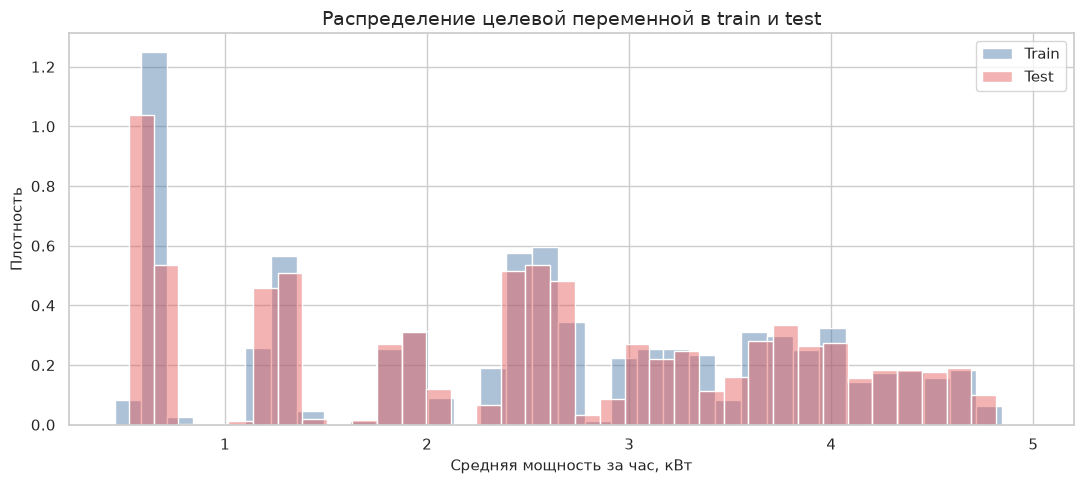

In [26]:
plt.figure(figsize=(11, 5))

sns.histplot(
    y_train,
    bins=35,
    stat="density",
    alpha=0.45,
    color="#4C78A8",
    label="Train",
)

sns.histplot(
    y_test,
    bins=35,
    stat="density",
    alpha=0.45,
    color="#E45756",
    label="Test",
)

plt.title("Распределение целевой переменной в train и test")
plt.xlabel("Средняя мощность за час, кВт")
plt.ylabel("Плотность")
plt.legend()
plt.tight_layout()
plt.show()

### Вывод по разделению данных

Данные разделены хронологически без перемешивания. Обучающая выборка содержит
13 691 наблюдение, а тестовая — 3 666 наблюдений. В обучающую выборку вошли
наблюдения с 10 января по 28 мая 2025 года, а в тестовую — более поздние
наблюдения с 28 мая по 1 июля 2025 года.

Среднее значение целевой переменной составляет около 2,51 кВт в обучающей
выборке и 2,46 кВт в тестовой. Распределения мощности в двух выборках похожи,
хотя полностью не совпадают, что естественно для хронологических данных.

Пересечения временных периодов нет. Следовательно, качество моделей будет
оцениваться на данных, которые относятся к более позднему периоду и не
использовались при обучении.

# Задачи:  
# Обучите модель линейной регрессии на разных наборах переменных и для разных спецификаций модели на обучающей выборке.    
# Сделайте предсказания целевой переменной для тестовой выборки
# Рассчитайте метрики качества
# Выберите спецификацию модели с наилучшим качеством

## 8. Обучение моделей линейной регрессии

Обучим четыре спецификации модели:

1. простая линейная регрессия по средней температуре;
2. простая линейная регрессия по номинальной мощности;
3. множественная линейная регрессия по числовым признакам;
4. множественная линейная регрессия с числовыми признаками и типом оборудования.

Все модели обучаются на одной обучающей выборке и оцениваются на одном
тестовом периоде.

Импорт моделей и метрик

In [27]:
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score,
)

Функция расчёта метрик

In [28]:
def calculate_regression_metrics(model_name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)

    return {
        "Модель": model_name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "MAPE, %": mean_absolute_percentage_error(y_true, y_pred) * 100,
        "R2": r2_score(y_true, y_pred),
    }

In [29]:
# списки для хранения результ предсказаний
models = {}
predictions = {}
metrics_results = []

Модель 1 — регрессия по температуре

In [30]:
model_1_features = ["temperature_avg_1h"]

model_1 = LinearRegression()

model_1.fit(
    X_train[model_1_features],
    y_train,
)

y_pred_1 = model_1.predict(
    X_test[model_1_features]
)

models["Модель 1: температура"] = model_1
predictions["Модель 1: температура"] = y_pred_1

metrics_results.append(
    calculate_regression_metrics(
        "Модель 1: температура",
        y_test,
        y_pred_1,
    )
)

print("Свободный коэффициент:", model_1.intercept_)
print("Коэффициент температуры:", model_1.coef_[0])

Свободный коэффициент: 1.365275072435315
Коэффициент температуры: 0.012985526364608762


Модель 2 — регрессия по номинальной мощности

In [31]:
model_2_features = ["nominal_power_kw"]

model_2 = LinearRegression()

model_2.fit(
    X_train[model_2_features],
    y_train,
)

y_pred_2 = model_2.predict(
    X_test[model_2_features]
)

models["Модель 2: номинальная мощность"] = model_2
predictions["Модель 2: номинальная мощность"] = y_pred_2

metrics_results.append(
    calculate_regression_metrics(
        "Модель 2: номинальная мощность",
        y_test,
        y_pred_2,
    )
)

print("Свободный коэффициент:", model_2.intercept_)
print("Коэффициент номинальной мощности:", model_2.coef_[0])

Свободный коэффициент: 2.0526502611370914
Коэффициент номинальной мощности: 0.017267000906327372


Модель 3 — множественная регрессия по числовым признакам

In [32]:
model_3_features = [
    "nominal_power_kw",
    "temperature_avg_1h",
    "machine_age_years",
    "readings_count_1h",
    "out_of_range_count_1h",
    "breakdowns_before",
    "maintenance_last_30d",
]

model_3 = LinearRegression()

model_3.fit(
    X_train[model_3_features],
    y_train,
)

y_pred_3 = model_3.predict(
    X_test[model_3_features]
)

models["Модель 3: числовые признаки"] = model_3
predictions["Модель 3: числовые признаки"] = y_pred_3

metrics_results.append(
    calculate_regression_metrics(
        "Модель 3: числовые признаки",
        y_test,
        y_pred_3,
    )
)

In [33]:
model_3_coefficients = pd.DataFrame({
    "Признак": model_3_features,
    "Коэффициент": model_3.coef_,
})

display(model_3_coefficients)
print("Свободный коэффициент:", model_3.intercept_)

,Признак,Коэффициент
0,nominal_power_kw,-0.1106
1,temperature_avg_1h,0.0628
2,machine_age_years,-0.0165
3,readings_count_1h,-0.0035
4,out_of_range_count_1h,0.0095
5,breakdowns_before,-0.0399
6,maintenance_last_30d,-0.0222


Свободный коэффициент: 0.4045329244176128


Модель 4 — регрессия с типом оборудования

machine_type_code является категориальной переменной. Преобразуем её методом One-Hot Encoding.  
Из этой модели исключаем nominal_power_kw, поскольку номинальная мощность практически однозначно связана с типом машины. Одновременное включение этих переменных может привести к мультиколлинеарности.

In [34]:
model_4_numeric_features = [
    "temperature_avg_1h",
    "machine_age_years",
    "readings_count_1h",
    "out_of_range_count_1h",
    "breakdowns_before",
    "maintenance_last_30d",
]

model_4_categorical_features = [
    "machine_type_code",
]

model_4_features = (
    model_4_numeric_features
    + model_4_categorical_features
)

In [35]:
model_4_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            "passthrough",
            model_4_numeric_features,
        ),
        (
            "machine_type",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore",
            ),
            model_4_categorical_features,
        ),
    ]
)

In [36]:
model_4 = Pipeline(
    steps=[
        ("preprocessor", model_4_preprocessor),
        ("regression", LinearRegression()),
    ]
)

model_4.fit(
    X_train[model_4_features],
    y_train,
)

y_pred_4 = model_4.predict(
    X_test[model_4_features]
)

models["Модель 4: тип оборудования"] = model_4
predictions["Модель 4: тип оборудования"] = y_pred_4

metrics_results.append(
    calculate_regression_metrics(
        "Модель 4: тип оборудования",
        y_test,
        y_pred_4,
    )
)

Сравнение качества моделей

In [37]:
metrics_df = (
    pd.DataFrame(metrics_results)
    .sort_values("R2", ascending=False)
    .reset_index(drop=True)
)

numeric_metric_cols = [
    "MAE",
    "MSE",
    "RMSE",
    "MAPE, %",
    "R2",
]

metrics_df[numeric_metric_cols] = (
    metrics_df[numeric_metric_cols].round(4)
)

display(metrics_df)

,Модель,MAE,MSE,RMSE,"MAPE, %",R2
0,Модель 4: тип оборудования,0.0723,0.0093,0.0967,3.5959,0.9944
1,Модель 3: числовые признаки,0.6897,0.7343,0.8569,55.8788,0.5619
2,Модель 1: температура,0.9034,1.3205,1.1491,72.3552,0.2122
3,Модель 2: номинальная мощность,1.0277,1.5251,1.2350,80.6278,0.0901


Графики истинных и предсказанных значений

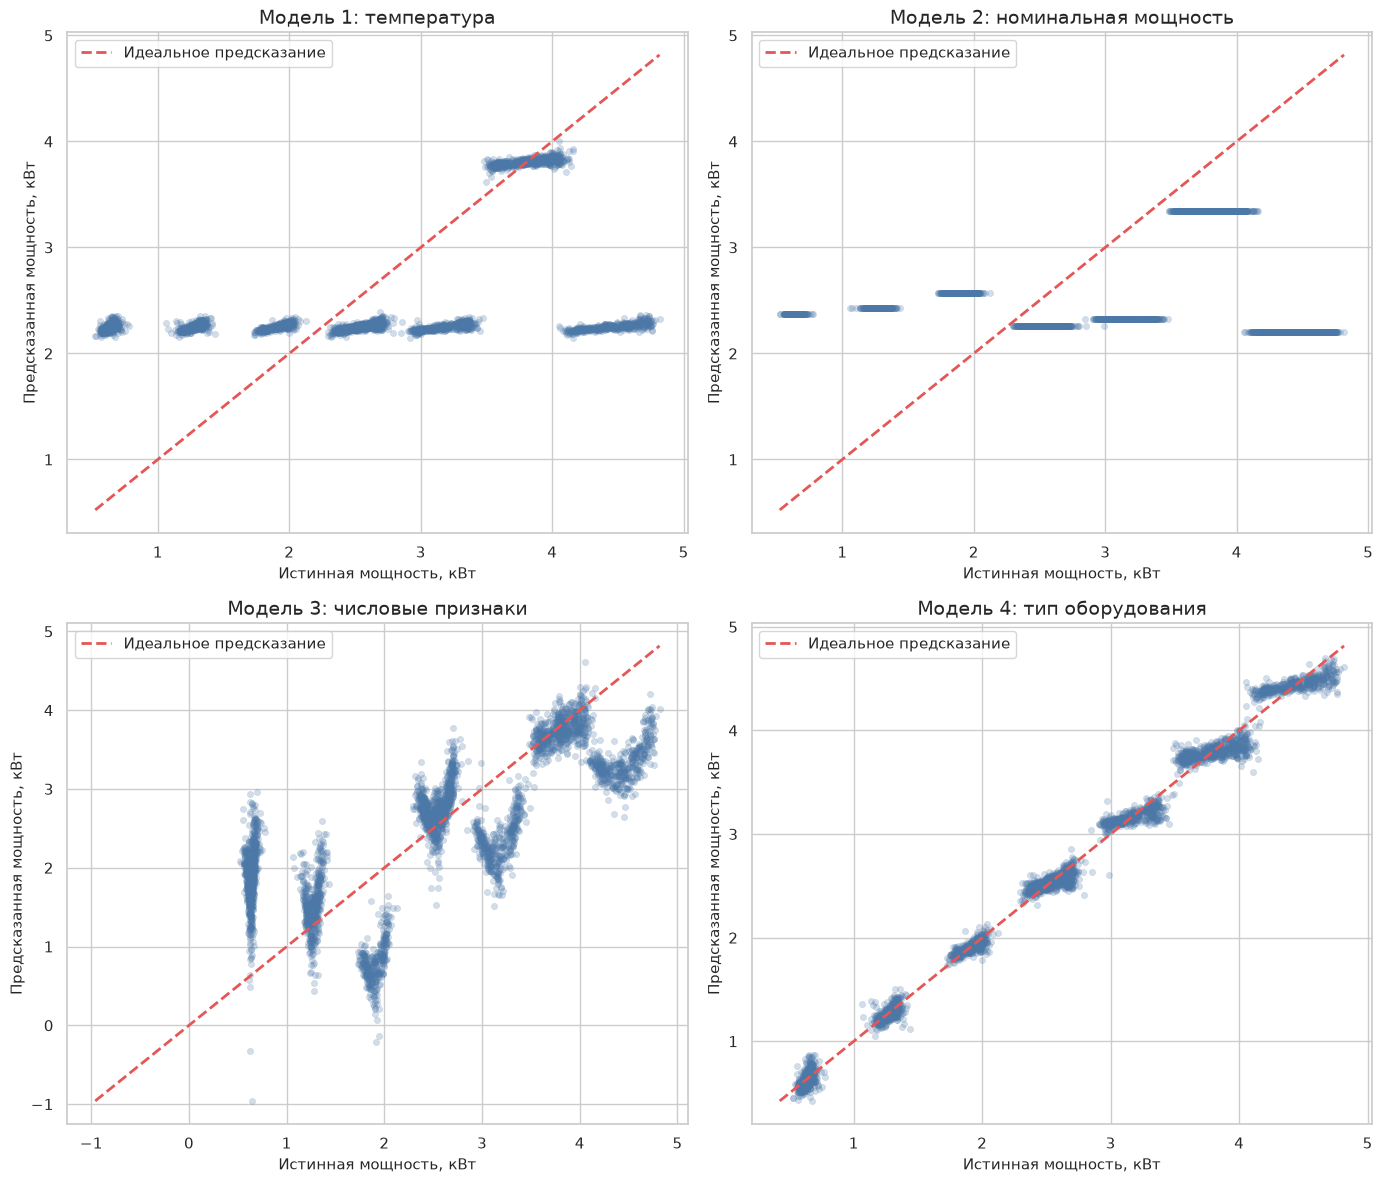

In [38]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

for ax, (model_name, y_pred) in zip(
    axes,
    predictions.items(),
):
    sns.scatterplot(
        x=y_test,
        y=y_pred,
        alpha=0.25,
        s=20,
        color="#4C78A8",
        edgecolor=None,
        ax=ax,
    )

    min_value = min(y_test.min(), y_pred.min())
    max_value = max(y_test.max(), y_pred.max())

    ax.plot(
        [min_value, max_value],
        [min_value, max_value],
        linestyle="--",
        color="#E45756",
        linewidth=2,
        label="Идеальное предсказание",
    )

    ax.set_title(model_name)
    ax.set_xlabel("Истинная мощность, кВт")
    ax.set_ylabel("Предсказанная мощность, кВт")
    ax.legend()

plt.tight_layout()
plt.show()

### Вывод по сравнению моделей

Наименьшее качество показала простая модель по номинальной мощности:
коэффициент детерминации R² составляет около 0,09. Причина заключается в том,
что зависимость между номинальной и фактической средней мощностью не является
единой линейной зависимостью для всех типов оборудования.

Модель только по температуре объясняет около 21% изменчивости target.
Множественная регрессия по числовым признакам повышает R² примерно до 0,56,
но её средняя абсолютная ошибка всё ещё составляет около 0,69 кВт.

Лучший результат получен после добавления типа оборудования. Четвёртая модель
имеет R² около 0,994, MAE около 0,072 кВт и MAPE около 3,60%. Следовательно,
тип оборудования является главным фактором, определяющим характерный уровень
его средней мощности.

Для дальнейшей интерпретации выбирается модель 4 — множественная линейная
регрессия с числовыми признаками и категориальным признаком типа машины.

# Задачи: 
# Сделайте выводы относительно полученной модели и ее качества
# Дайте содержательную интерпретацию полученным зависимостям
# Разместите блокнот в GitHub и прикрепите ссылку на блокнот в удаленном репозитории

Интерпретация лучшей модели

## 9. Содержательная интерпретация лучшей модели

Лучшей спецификацией оказалась модель 4, использующая числовые характеристики
и тип оборудования. Для интерпретации извлечём свободный коэффициент и
коэффициенты всех преобразованных признаков.

При One-Hot Encoding одна категория автоматически исключается и становится
базовой. Коэффициенты остальных типов оборудования показывают отличие от
базовой категории при одинаковых значениях других признаков.

Извлечение коэффициентов

In [39]:
best_preprocessor = model_4.named_steps["preprocessor"]
best_regression = model_4.named_steps["regression"]

feature_names = best_preprocessor.get_feature_names_out()

clean_feature_names = (
    pd.Series(feature_names)
    .str.replace("numeric__", "", regex=False)
    .str.replace(
        "machine_type__machine_type_code_",
        "machine_type=",
        regex=False,
    )
)

coefficients_df = pd.DataFrame({
    "Признак": clean_feature_names,
    "Коэффициент": best_regression.coef_,
})

coefficients_df["Коэффициент"] = (
    coefficients_df["Коэффициент"].round(6)
)

display(coefficients_df)

print(
    "Свободный коэффициент:",
    round(best_regression.intercept_, 6),
)

,Признак,Коэффициент
0,temperature_avg_1h,0.0291
1,machine_age_years,-0.0007
2,readings_count_1h,-0.0000
3,out_of_range_count_1h,-0.0002
4,breakdowns_before,0.0005
5,maintenance_last_30d,0.0015
6,machine_type=CNC_MILL,0.6321
7,machine_type=OVEN,-0.3191
8,machine_type=PACK,3.8041
9,machine_type=PRESS,1.2674


Свободный коэффициент: -1.338817


Проверка базовой категории

In [41]:
encoder = (
    best_preprocessor
    .named_transformers_["machine_type"]
)

print(
    "Все категории:",
    encoder.categories_[0],
)

print(
    "Базовая категория:",
    encoder.categories_[0][0],
)

Все категории: ['CNC_LATHE' 'CNC_MILL' 'OVEN' 'PACK' 'PRESS' 'ROBOT' 'WELDER']
Базовая категория: CNC_LATHE


### Интерпретация коэффициентов

Базовой категорией является `CNC_LATHE`. Коэффициенты категориальных признаков
показывают отличие соответствующего типа машины от `CNC_LATHE` при одинаковых
значениях температуры, возраста и других признаков.

- При увеличении средней температуры на 1 °C прогнозируемая средняя мощность
  увеличивается примерно на 0,029 кВт при неизменных остальных признаках.

- Увеличение возраста оборудования на один год связано с уменьшением
  прогнозируемой мощности примерно на 0,0007 кВт. Практический размер этого
  эффекта крайне мал.

- Дополнительное сенсорное измерение за час изменяет прогноз менее чем
  на 0,0001 кВт. Этот коэффициент также практически мал.

- После учёта температуры и типа оборудования количество выходов за норматив,
  число прошлых поломок и недавнее обслуживание имеют очень небольшие
  коэффициенты. Их самостоятельное влияние на среднюю мощность невелико.

- Для типа `CNC_MILL` прогнозируемая мощность примерно на 0,63 кВт выше,
  чем для базового типа `CNC_LATHE`.

- Для типа `PACK` условная разница с `CNC_LATHE` составляет около 3,80 кВт,
  для `PRESS` — 1,27 кВт, для `ROBOT` — 1,90 кВт, а для `WELDER` — 2,53 кВт.

- Коэффициент `OVEN` равен примерно −0,32 кВт. Это не означает, что печи
  потребляют меньше энергии. Печи работают при значительно более высокой
  температуре, влияние которой уже учтено отдельным коэффициентом. Поэтому
  коэффициент типа показывает только оставшуюся условную разницу при одинаковой
  температуре и других признаках.

Свободный коэффициент нельзя содержательно интерпретировать как реальную
мощность, поскольку он соответствует ситуации, когда все числовые признаки
равны нулю, что находится за пределами наблюдаемых режимов эксплуатации.

Сравнение качества на train и test

In [42]:
y_pred_train_4 = model_4.predict(
    X_train[model_4_features]
)

train_test_metrics = pd.DataFrame([
    calculate_regression_metrics(
        "Train",
        y_train,
        y_pred_train_4,
    ),
    calculate_regression_metrics(
        "Test",
        y_test,
        y_pred_4,
    ),
])

train_test_metrics = train_test_metrics.rename(
    columns={"Модель": "Выборка"}
)

train_test_metrics[numeric_metric_cols] = (
    train_test_metrics[numeric_metric_cols].round(4)
)

display(train_test_metrics)

,Выборка,MAE,MSE,RMSE,"MAPE, %",R2
0,Train,0.0741,0.0100,0.0999,3.5377,0.9937
1,Test,0.0723,0.0093,0.0967,3.5959,0.9944


Метрики на обучающей и тестовой выборках практически совпадают. На тестовых
данных качество не ухудшилось: MAE составляет около 0,072 кВт, а R² —
около 0,994. Следовательно, явных признаков переобучения не наблюдается.

Анализ остатков

In [43]:
test_results = test_df[
    [
        "prediction_time",
        "machine_type_code",
        target_col,
    ]
].copy()

test_results["predicted_power"] = y_pred_4

test_results["residual"] = (
    test_results[target_col]
    - test_results["predicted_power"]
)

test_results["absolute_error"] = (
    test_results["residual"].abs()
)

display(test_results.head())

,prediction_time,machine_type_code,power_avg_1h,predicted_power,residual,absolute_error
13728,2025-05-28 09:00:00+11:00,OVEN,3.6926,3.7334,-0.0408,0.0408
13729,2025-05-28 10:00:00+11:00,OVEN,3.9534,3.8783,0.0752,0.0752
13730,2025-05-28 15:00:00+11:00,OVEN,3.5983,3.7569,-0.1586,0.1586
13731,2025-05-28 15:00:00+11:00,ROBOT,2.4118,2.5061,-0.0943,0.0943
13732,2025-05-28 15:00:00+11:00,PACK,4.2103,4.3664,-0.1561,0.1561


Графики остатков

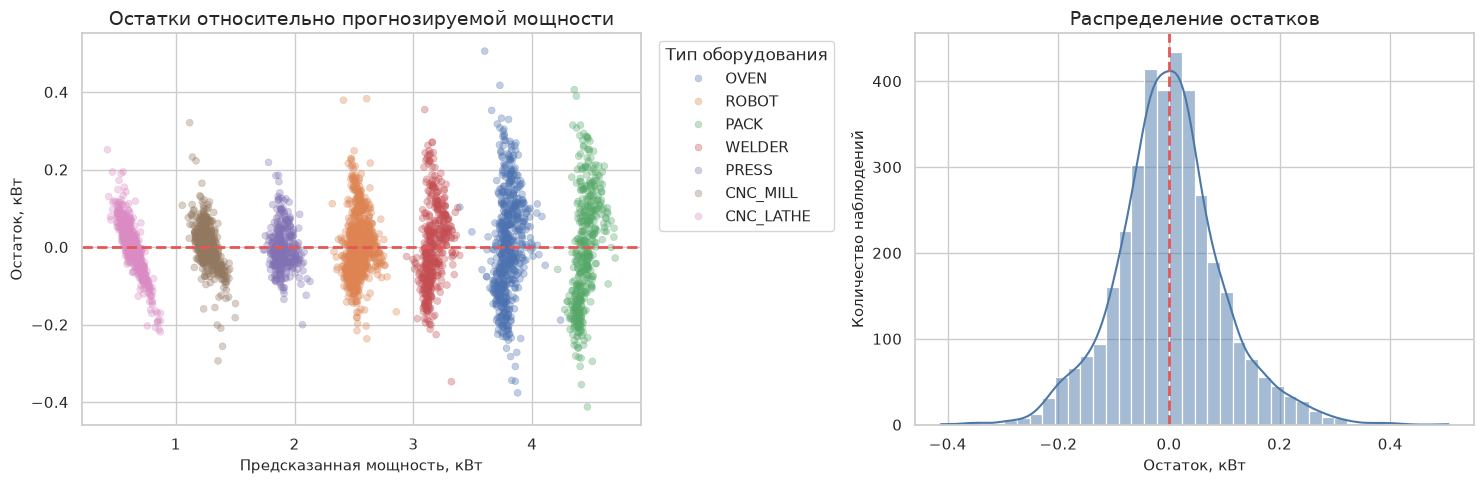

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.scatterplot(
    data=test_results,
    x="predicted_power",
    y="residual",
    hue="machine_type_code",
    alpha=0.35,
    s=25,
    edgecolor=None,
    ax=axes[0],
)

axes[0].axhline(
    0,
    color="#E45756",
    linestyle="--",
    linewidth=2,
)

axes[0].set_title("Остатки относительно прогнозируемой мощности")
axes[0].set_xlabel("Предсказанная мощность, кВт")
axes[0].set_ylabel("Остаток, кВт")
axes[0].legend(
    title="Тип оборудования",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

sns.histplot(
    data=test_results,
    x="residual",
    bins=40,
    kde=True,
    color="#4C78A8",
    ax=axes[1],
)

axes[1].axvline(
    0,
    color="#E45756",
    linestyle="--",
    linewidth=2,
)

axes[1].set_title("Распределение остатков")
axes[1].set_xlabel("Остаток, кВт")
axes[1].set_ylabel("Количество наблюдений")

plt.tight_layout()
plt.show()

Численные характеристики остатков

In [45]:
residual_summary = (
    test_results["residual"]
    .describe()
    .to_frame("Значение")
)

display(residual_summary)

print(
    "Средний остаток:",
    round(test_results["residual"].mean(), 6),
)

,Значение
count,"3,666.0000"
mean,0.0009
std,0.0967
min,-0.4125
25%,-0.0541
50%,-0.0007
75%,0.0522
max,0.5055


Средний остаток: 0.00087


Это очень близко к нулю и указывает на отсутствие заметного общего смещения прогнозов.

Ошибки по типам оборудования

In [46]:
errors_by_type = (
    test_results
    .groupby("machine_type_code")
    .agg(
        observations=("absolute_error", "size"),
        actual_mean=(target_col, "mean"),
        predicted_mean=("predicted_power", "mean"),
        MAE=("absolute_error", "mean"),
        mean_residual=("residual", "mean"),
    )
    .sort_values("MAE")
    .round(4)
)

display(errors_by_type)

,observations,actual_mean,predicted_mean,MAE,mean_residual
machine_type_code,,,,,
CNC_MILL,448,1.2671,1.2658,0.0441,0.0014
PRESS,322,1.9032,1.9054,0.0451,-0.0022
CNC_LATHE,709,0.6343,0.6307,0.0453,0.0037
ROBOT,732,2.5371,2.5366,0.0643,0.0005
WELDER,422,3.1704,3.1684,0.0854,0.0021
OVEN,601,3.8024,3.7977,0.1051,0.0047
PACK,432,4.4379,4.4457,0.1214,-0.0078


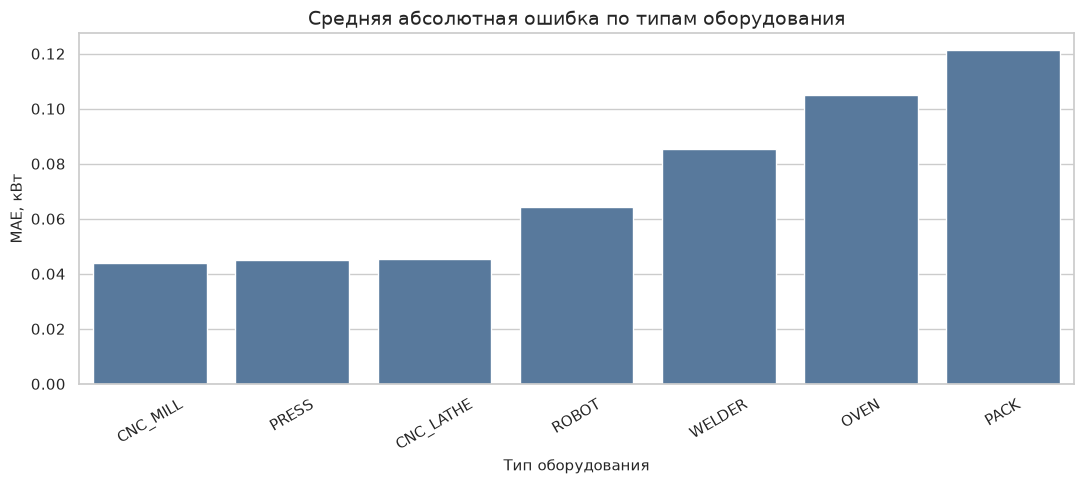

In [47]:
plt.figure(figsize=(11, 5))

error_plot_df = (
    errors_by_type
    .reset_index()
)

sns.barplot(
    data=error_plot_df,
    x="machine_type_code",
    y="MAE",
    color="#4C78A8",
)

plt.title("Средняя абсолютная ошибка по типам оборудования")
plt.xlabel("Тип оборудования")
plt.ylabel("MAE, кВт")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 13. Итоговые выводы

В работе решалась задача прогнозирования средней мощности промышленного
оборудования за час. В качестве целевой переменной использовалась
`power_avg_1h`.

Были обучены четыре спецификации линейной регрессии. Простые модели по
температуре и номинальной мощности показали низкое качество: их R² составил
примерно 0,21 и 0,09 соответственно. Это означает, что одного признака
недостаточно для описания различий между машинами.

Множественная регрессия по числовым признакам повысила R² до 0,56. Лучший
результат показала модель, дополненная категориальным признаком типа
оборудования:

- R² на тестовой выборке — 0,9944;
- MAE — 0,0723 кВт;
- RMSE — 0,0967 кВт;
- MAPE — 3,60%.

Модель объясняет около 99,44% изменчивости целевой переменной. Метрики на
обучающей и тестовой выборках близки, поэтому явных признаков переобучения
не обнаружено. Средний остаток близок к нулю, следовательно, модель в целом
не склонна систематически завышать или занижать прогноз.

Наиболее важным фактором оказался тип оборудования. Разные типы машин имеют
различные характерные уровни энергопотребления. После учёта типа машины
дополнительное влияние возраста, предыдущих поломок и недавнего обслуживания
оказалось небольшим. Температура сохраняет положительную связь с мощностью:
увеличение средней температуры на 1 °C связано с увеличением прогнозируемой
мощности примерно на 0,029 кВт при неизменных остальных признаках.

Наибольшие средние ошибки наблюдаются для типов PACK и OVEN, однако даже для
них MAE остаётся небольшим. Полученную модель можно использовать для оценки
ожидаемого уровня мощности и поиска наблюдений, в которых фактическое
энергопотребление заметно отличается от прогнозируемого.

Высокое качество частично объясняется синтетическим характером базы:
энергопотребление тесно связано с заданным типом оборудования. Результаты
показывают статистические зависимости внутри этого набора данных и не должны
интерпретироваться как доказательство причинного влияния признаков.

Регрессионная задача является отдельным учебным этапом проекта. Она
прогнозирует среднюю мощность, а не вероятность будущей поломки
`failure_next_6h`.